# Lectura y comparación de archivos con Pandas
Formatos: CSV y JSON
Objetivo: cargar cada archivo como un DataFrame, explorar su estructura y comparar sus características.

Para el desarrollo de este proyecto se seleccionó como tema el análisis de las condiciones meteorológicas asociadas a las alertas de incendios en el departamento del Tolima. La idea surge de la importancia de analizar cómo diferentes condiciones ambientales pueden estar relacionadas con la presencia de alertas de incendios en los municipios del departamento.

Para realizar el análisis se seleccionaron dos fuentes de datos. La primera corresponde al conjunto de datos Alertas de Incendios, obtenido mediante un archivo CSV descargado de la plataforma de Datos Abiertos Colombia. Esta fuente contiene información como el departamento, municipio, código DANE, nivel de amenaza y fecha de ejecución de la alerta.

La segunda fuente corresponde a información disponible a través de una API REST relacionada con el IDEAM, la cual fue consultada directamente desde Python. De esta manera, el proyecto permite trabajar con dos formas diferentes de obtención de datos: un archivo descargado manualmente y una fuente consultada mediante una API.

Inicialmente se realizó la extracción y exploración de ambas fuentes, revisando sus dimensiones, columnas, tipos de datos y valores faltantes. Posteriormente, los datos fueron cargados en una base de datos SQLite para realizar consultas mediante SQL y evaluar las posibilidades de integración entre las fuentes.


In [ ]:
# 1. Carga de los archivos correspondientes

import pandas as pd
from google.colab import files
import requests
import os
import json

archivos_subidos = files.upload()

Saving alertas_incendios.csv to alertas_incendios.csv


In [ ]:
# 2. Leer el archivo CSV y consultar la API

import pandas as pd
import requests

# FUENTE 1: archivo CSV de alertas de incendios
df_incendios = pd.read_csv(
    "alertas_incendios.csv",
    delimiter=";"
)

print("CSV de alertas cargado correctamente.")

# FUENTE 2: catálogo nacional de estaciones del IDEAM
url_ideam = "https://www.datos.gov.co/resource/hp9r-jxuu.json"

# Parámetro para solicitar hasta 50.000 registros
parametros = {"$limit": 50000}

# Consultar la API
respuesta = requests.get(
    url_ideam,
    params=parametros,
    timeout=60
)

# Comprobar si la consulta fue exitosa
respuesta.raise_for_status()

# Convertir los datos recibidos a un DataFrame
datos_ideam = respuesta.json()
df_ideam = pd.DataFrame(datos_ideam)

print("API consultada correctamente.")

# Mostrar las dimensiones de las dos fuentes
print("\nIncendios:", df_incendios.shape)
print("IDEAM:", df_ideam.shape)

# Mostrar los departamentos del catálogo
if "departamento" in df_ideam.columns:
    print("\nDepartamentos encontrados en el catálogo:")
    print(df_ideam["departamento"].value_counts().head(20))
else:
    print("\nNo se encontró la columna 'departamento'.")
    print("Columnas disponibles:", df_ideam.columns.tolist())


CSV de alertas cargado correctamente.
API consultada correctamente.

Incendios: (41195, 7)
IDEAM: (19848, 19)

Departamentos encontrados en el catálogo:
departamento
Antioquia             3070
Cundinamarca          2298
Valle Del Cauca       1674
Boyacá                1102
Santander             1082
Tolima                1042
Caldas                 890
Cauca                  782
Huila                  782
Bogotá                 742
Bolivar                636
Norte De Santander     594
Cesar                  554
La Guajira             518
Cordoba                464
Risaralda              444
Meta                   442
Magdalena              404
Nariño                 336
Choco                  260
Name: count, dtype: int64


# INTERPRETACION

la eextracción inicial funciono correctamente y ambas fuentes pudieron ser cargadas en python
la fuente de alertas contiene una cantidad considerablemente mayor de registros, mientras que la API devuelve 221 registros con 15 variables.

In [ ]:
display(df_incendios.head())

,OBJECTID,REGION,DEPARTAMENTO,MUNICIPIO,COD_DANE,TEXTO_AMENAZA,FECHA_EJECUCION
0,1.0,ANDINA,"BOGOTÁ, D.C.","BOGOTÁ, D.C.",11001.0,ALTA,1/01/2026
1,2.0,CARIBE,BOLÍVAR,EL CARMEN DE BOLÍVAR,13244.0,ALTA,1/01/2026
2,3.0,ANDINA,BOYACÁ,AQUITANIA,15047.0,ALTA,1/01/2026
3,4.0,ANDINA,BOYACÁ,ARCABUCO,15051.0,ALTA,1/01/2026
4,5.0,ANDINA,BOYACÁ,BELÉN,15087.0,ALTA,1/01/2026


# INTERPRETACION
el resultado nos muetsra las 7 columnas de infromacion correctamrnte

Los primeros cinco registros corresponden a diferentes departamentos y municipios, y todos presentan en este fragmento un nivel de amenaza ALTA y la fecha 01/01/2026

Esto nos da la informacion territorial y temporal de las alertas para posteriormente relacionar dicha informacion con la infromacion de estaciones del IDEAM

In [ ]:
display(df_ideam.head())

,codigo,nombre,categoria,tecnologia,estado,departamento,municipio,ubicaci_n,altitud,longitud,latitud,fecha_instalacion,area_operativa,area_hidrografica,zona_hidrografica,subzona_hidrografica,entidad,corriente,fecha_suspension
0,0024030700,COVARACHIA [24030700],Pluviométrica,Convencional,Activa,Boyacá,Covarachía,"{'latitude': '-72.739228889', 'longitude': '6....",2244,-72.739228889,6.500608056,15/06/1974,Area Operativa 06 - Boyacá-Casanare-Vichada,Magdalena Cauca,Sogamoso,Río Chicamocha,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,NaN,NaN
1,0035075040,INSTITUCION AGRICOLA MACANAL [35075040],Climatológica Principal,Convencional,Activa,Boyacá,Macanal,"{'latitude': '-73.316151944', 'longitude': '4....",1742,-73.316151944,4.974416111,15/07/1982,Area Operativa 06 - Boyacá-Casanare-Vichada,Orinoco,Meta,Río Garagoa,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,NaN,NaN
2,0035070170,NAZARETH [35070170],Pluviométrica,Convencional,Activa,Boyacá,Santa María,"{'latitude': '-73.219595', 'longitude': '4.735...",439,-73.219595,4.735228889,15/09/1972,Area Operativa 06 - Boyacá-Casanare-Vichada,Orinoco,Meta,Río Guavio,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,NaN,NaN
3,0035190030,CHAMEZA [35190030],Pluviográfica,Convencional,Activa,Casanare,Chámeza,"{'latitude': '-72.871813889', 'longitude': '5....",1129,-72.871813889,5.215341944,15/11/1974,Area Operativa 06 - Boyacá-Casanare-Vichada,Orinoco,Meta,Río Cusiana,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,NaN,NaN
4,0035060220,LA GLORIA [35060220],Pluviométrica,Convencional,Activa,Cundinamarca,Ubalá,"{'latitude': '-73.41977778', 'longitude': '4.8...",1845,-73.41977778,4.815694444,15/09/1964,Area Operativa 11 - Cundinamarca-Amazonas,Orinoco,Meta,Río Guavio,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,NaN,NaN


# Interpretacion

la advertencia del principio es de colab ya que trata de interpretar automaticamene algunas columnas como fechas durante la visualizacion

se observara variables relacionadas con el catalogo de estaciones, como el codigo, nombre, categoria, estado, departamento, municipio, ubicacion, altitud y fechas de instalación o suspension, en los primeros registros se identificaron estaciones de diferentes categorias, entre ellas pluviometricas, agrometeorologicas y limnimetricas

La exploracion permitió identificar que las fuentes tienen estructuras diferentes, la fuente de incendios contiene registros de alertas asociados a municipios y fechas, mientras que la fuente del IDEAM contiene informacion sobre las estaciones, entonces sera necesario analizar las variables disponibles antes de establecer una relacion entre ambas fuentes

In [ ]:
# 3. Exploración de estructuras y tipos de dato

def explorar(nombre, df):
#creamos la funcion explorar la cual tendra el nombre para identificar la fuente y el dataframe a analizar
    print('\n' + '=' * 60)
#Esto es para separar visualemnete cada fuente el \n agrega un salto de linea
    print(nombre)
    print('=' * 60)
    print('Dimensiones:', df.shape)
    print('Columnas:')
    print(list(df.columns))
    print('Tipos de datos:')
    print(df.dtypes)
    print('Valores faltantes:')
    print(df.isnull().sum())
    print('Primeros registros:')
    display(df.head())

In [ ]:
explorar('CSV - Alertas de Incendios', df_incendios)


CSV - Alertas de Incendios
Dimensiones: (41195, 7)
Columnas:
['OBJECTID', 'REGION', 'DEPARTAMENTO', 'MUNICIPIO', 'COD_DANE', 'TEXTO_AMENAZA', 'FECHA_EJECUCION']
Tipos de datos:
OBJECTID           float64
REGION              object
DEPARTAMENTO        object
MUNICIPIO           object
COD_DANE           float64
TEXTO_AMENAZA       object
FECHA_EJECUCION     object
dtype: object
Valores faltantes:
OBJECTID           1
REGION             1
DEPARTAMENTO       1
MUNICIPIO          1
COD_DANE           1
TEXTO_AMENAZA      1
FECHA_EJECUCION    0
dtype: int64
Primeros registros:


,OBJECTID,REGION,DEPARTAMENTO,MUNICIPIO,COD_DANE,TEXTO_AMENAZA,FECHA_EJECUCION
0,1.0,ANDINA,"BOGOTÁ, D.C.","BOGOTÁ, D.C.",11001.0,ALTA,1/01/2026
1,2.0,CARIBE,BOLÍVAR,EL CARMEN DE BOLÍVAR,13244.0,ALTA,1/01/2026
2,3.0,ANDINA,BOYACÁ,AQUITANIA,15047.0,ALTA,1/01/2026
3,4.0,ANDINA,BOYACÁ,ARCABUCO,15051.0,ALTA,1/01/2026
4,5.0,ANDINA,BOYACÁ,BELÉN,15087.0,ALTA,1/01/2026


# INTERPRETACION
En la exploracion inicial de la fuente de Alertas de Incendios se encontraron 41.195 registros y 7 variables las cuales contienen informacion sobre la region departamento municipio codigo DANE nivel de amnaza y fecha de ejecucion de cada registro

En los tipos de datos se puede observar que las variables de region departamento municipio y texto de amnaza estan como texto mientras que OBJECTID y COD_DANE aparecen como float64 tambien se observa que FECHA_EJECUCION esta como object aunque contiene fechas por lo que mas adelante se tendria que convertir a un formato de fecha para poder trabajar mejor con ella

Tambien se encontraron 6 valores faltantes en total los cuales estan distribuidos en OBJECTID REGION DEPARTAMENTO MUNICIPIO COD_DANE y TEXTO_AMENAZA mientras que FECHA_EJECUCION no tiene valores faltantes esto muestra que existe por lo menos un registro que tiene informacion incompleta y que mas adelante se tendra que revisar para decidir que tratamiento darle

Al revisar los primeros registros se puede observar que la fuente contiene informacion de diferentes departamentos y municipios y que tambien registra el nivel de amnaza y la fecha de cada registro esto permite comprobar que los datos fueron cargados correctamente y que la estructura de la fuente sirve para continuar con el analisis

In [ ]:
explorar('API - IDEAM', df_ideam)


API - IDEAM
Dimensiones: (19848, 19)
Columnas:
['codigo', 'nombre', 'categoria', 'tecnologia', 'estado', 'departamento', 'municipio', 'ubicaci_n', 'altitud', 'longitud', 'latitud', 'fecha_instalacion', 'area_operativa', 'area_hidrografica', 'zona_hidrografica', 'subzona_hidrografica', 'entidad', 'corriente', 'fecha_suspension']
Tipos de datos:
codigo                  object
nombre                  object
categoria               object
tecnologia              object
estado                  object
departamento            object
municipio               object
ubicaci_n               object
altitud                 object
longitud                object
latitud                 object
fecha_instalacion       object
area_operativa          object
area_hidrografica       object
zona_hidrografica       object
subzona_hidrografica    object
entidad                 object
corriente               object
fecha_suspension        object
dtype: object
Valores faltantes:
codigo                      0
n

,codigo,nombre,categoria,tecnologia,estado,departamento,municipio,ubicaci_n,altitud,longitud,latitud,fecha_instalacion,area_operativa,area_hidrografica,zona_hidrografica,subzona_hidrografica,entidad,corriente,fecha_suspension
0,0024030700,COVARACHIA [24030700],Pluviométrica,Convencional,Activa,Boyacá,Covarachía,"{'latitude': '-72.739228889', 'longitude': '6....",2244,-72.739228889,6.500608056,15/06/1974,Area Operativa 06 - Boyacá-Casanare-Vichada,Magdalena Cauca,Sogamoso,Río Chicamocha,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,NaN,NaN
1,0035075040,INSTITUCION AGRICOLA MACANAL [35075040],Climatológica Principal,Convencional,Activa,Boyacá,Macanal,"{'latitude': '-73.316151944', 'longitude': '4....",1742,-73.316151944,4.974416111,15/07/1982,Area Operativa 06 - Boyacá-Casanare-Vichada,Orinoco,Meta,Río Garagoa,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,NaN,NaN
2,0035070170,NAZARETH [35070170],Pluviométrica,Convencional,Activa,Boyacá,Santa María,"{'latitude': '-73.219595', 'longitude': '4.735...",439,-73.219595,4.735228889,15/09/1972,Area Operativa 06 - Boyacá-Casanare-Vichada,Orinoco,Meta,Río Guavio,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,NaN,NaN
3,0035190030,CHAMEZA [35190030],Pluviográfica,Convencional,Activa,Casanare,Chámeza,"{'latitude': '-72.871813889', 'longitude': '5....",1129,-72.871813889,5.215341944,15/11/1974,Area Operativa 06 - Boyacá-Casanare-Vichada,Orinoco,Meta,Río Cusiana,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,NaN,NaN
4,0035060220,LA GLORIA [35060220],Pluviométrica,Convencional,Activa,Cundinamarca,Ubalá,"{'latitude': '-73.41977778', 'longitude': '4.8...",1845,-73.41977778,4.815694444,15/09/1964,Area Operativa 11 - Cundinamarca-Amazonas,Orinoco,Meta,Río Guavio,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,NaN,NaN


# INTERPRETACION
En la exploracion inicial de la API del IDEAM se encontraron 221 registros y 15 variables, la informacion corresponde principalmente a datos de las estaciones como codigo nombre categoria estado departamento municipio ubicacion altitud fechas de instalacion y suspension entre otros campos

Se puede observar que todos los campos aparecen como object lo que significa que python los esta manejando como texto incluso en variables que contienen datos numericos o fechas como altitud y fecha de instalcion, esto se tendra que revisar mas adelante durante la etapa de transformacion de los datos

En cuanto a los valores faltantes se encontraron 157 en la variable corriente y 125 en fecha_suspension para un total de 282 valores faltantes. Estos valores no necesariamente representan errores ya que por ejemplo fecha_suspension aparece vacia en varias estaciones que se encuentran activas por lo que primero se debe revisar el significado de cada campo antes de realizar alguna eliminacion

Tambien se genero una advertencia relacionada con el formato de las fechas debido a que los datos utilizan el formato dia mes año. Esto se tendra en cuenta posteriormente cuando se realice la conversion de las fechas

In [ ]:
# 4. Tabla comparativa de las fuentes

comparacion = pd.DataFrame({
    'Fuente': ['Alertas de Incendios', 'Catálogo de estaciones IDEAM'],
    'Formato': ['CSV', 'JSON - API'],
    'Filas': [df_incendios.shape[0],df_ideam.shape[0]],
    'Columnas': [df_incendios.shape[1], df_ideam.shape[1]],
    'Valores_faltantes': [df_incendios.isnull().sum().sum(), df_ideam.isnull().sum().sum()]})

display(comparacion)

,Fuente,Formato,Filas,Columnas,Valores_faltantes
0,Alertas de Incendios,CSV,41195,7,6
1,Catálogo de estaciones IDEAM,JSON - API,19848,19,25820


# Interpretacion
La tabla comparativa permite observar las principales diferencias entre las dos fuentes utilizadas en el proyecto, la fuente de Alertas de Incendios contiene 41.195 filas y 7 columnas mientras que el Catalogo de estaciones IDEAM contiene 221 filas y 15 columnas

Tambien se puede observar que las fuentes tienen diferentes formatos de obtencion ya que las alertas de incendios se encuentran en un archivo CSV mientras que la informacion del IDEAM se obtiene mediante una API en formato JSON, esto permite trabajar con dos formas diferentes de extraccion de datos dentro del proyecto

En cuanto a los valores faltantes la fuente de alertas de Incendios presenta 6 valores mientras que el Catalogo de estaciones IDEAM presenta 282, estos valores no se consideran automaticamente como errores ya que algunos pueden corresponder a campos que no aplican para determinadas estaciones o a informacion que no se encuentra registrada

Esta comparacion permite tener una vision general de las fuentes antes de realizar las siguientes etapas de transformacion y posible integracion de los dato

#Consumo de una API REST con Python

Tema: Consulta de una API pública, validación de la respuesta y conversión de JSON a DataFrame

Objetivo
Consultar una API pública usando Python, validar la respuesta recibida, convertir el contenido JSON en un DataFrame y explorar su estructura básica.

In [ ]:
# Consumo de una API REST con Python
# Fuente: Datos Abiertos Colombia - IDEAM
# Objetivo: consultar una API pública, validar la respuesta,
# convertir el JSON recibido en DataFrame y explorar su estructura.

import requests
import pandas as pd

In [ ]:
# 1. Definición del endpoint y realización de la solicitud GET

url = "https://www.datos.gov.co/api/v3/views/cqmv-a99d/query.json"
#Aqui guardamos el endpoint de la APi en la variable url
#El endpoint es del catalogo de estacion del IDEAM
print("Endpoint consultado:", url)

try:
    response = requests.get(url, timeout=15)
    print("Código de respuesta:", response.status_code)
#Aca hacemos una solicitud a la APi para traer la informacion disponible
except requests.exceptions.RequestException as error:
    response = None
    print("No fue posible realizar la consulta:", error)

Endpoint consultado: https://www.datos.gov.co/api/v3/views/cqmv-a99d/query.json
Código de respuesta: 200


El resultado muestra que el endpoint consultado fue alcanzado correctamente y que la API devolvio un codigo de respuesta 200, esto confirma que la fuente puede ser consumida mediante una solicitud REST desde Python

In [ ]:
# 2. Validación de la respuesta

if response is not None:
    if response.status_code == 200:
        print("Solicitud exitosa.")
    else:
        print("La API respondió con un error:", response.status_code)
else:
    print("No existe una respuesta para validar.")

Solicitud exitosa.


In [ ]:
#Convertir la respuesta Json a Dataframe

In [ ]:
data = response.json()

In [ ]:
# 3. Conversión de la respuesta JSON a una estructura de Python

if response is not None and response.status_code == 200:
    data = response.json()
    print("Tipo de estructura recibida:", type(data))
    if isinstance(data, list):
        print("Número de registros:", len(data))
        print("Primeros registros:")
        display(data[:2])
    else:
        print("La respuesta no tiene formato de lista.")
else:
    data = []
    print("No se pudieron obtener los datos.")

Tipo de estructura recibida: <class 'list'>
Número de registros: 442
Primeros registros:


[{'codigo': '0035057040',
  'nombre': 'PUENTE CARRETERA QDA SALINAS [35057040]',
  'categoria': 'Limnimétrica',
  'estado': 'Activa',
  'departamento': 'Meta',
  'municipio': 'Restrepo',
  'ubicaci_n': {'type': 'Point', 'coordinates': [4.198344444, -73.570101]},
  'altitud': '390',
  'fecha_instalacion': '15/10/1978',
  'corriente': 'RÍO SALINAS',
  ':id': 'row-hpu5~xg54_4buy',
  ':version': 'rv-a439~i3cs.6w66',
  ':created_at': '2026-06-19T11:07:25.503Z',
  ':updated_at': '2026-06-19T11:07:25.503Z'},
 {'codigo': '0032060050',
  'nombre': 'LEJANIAS [32060050]',
  'categoria': 'Pluviométrica',
  'estado': 'Suspendida',
  'departamento': 'Meta',
  'municipio': 'Lejanías',
  'ubicaci_n': {'type': 'Point', 'coordinates': [3.533333333, -74.01666667]},
  'altitud': '680',
  'fecha_instalacion': '15/09/1979',
  'fecha_suspension': '15/07/1990',
  ':id': 'row-vamy.s7sm.nh52',
  ':version': 'rv-f337-nc9i-82a4',
  ':created_at': '2026-10-28T13:24:23.292Z',
  ':updated_at': '2026-10-28T13:24:23.2

# Interpretacion
En este bloque se convirtio la respuesta recibida de la API en una estructura que puede ser manejada por Python y se verifico el tipo de informacion recibida

El resultado muestra que la respuesta tiene una estructura de tipo lista y contiene 221 registros. Al revisar los primeros registros se puede observar que cada uno corresponde a una estacion del IDEAM y contiene informacion como codigo nombre categoria estado departamento municipio ubicacion altitud y fecha de instalacion

Tambien se observa que algunos campos pueden estar vacios dependiendo de la estacion y que la ubicacion contiene coordenadas geograficas. Esta exploracion permite conocer mejor la estructura de los datos antes de convertirlos en un DataFrame y continuar con el procesamiento de la informacion

In [ ]:
df_ideam_api = pd.DataFrame(data)

print("Dimensiones:", df_ideam_api.shape)

print("\nColumnas:")
print(df_ideam_api.columns.tolist())

df_ideam_api.info()

Dimensiones: (442, 15)

Columnas:
['codigo', 'nombre', 'categoria', 'estado', 'departamento', 'municipio', 'ubicaci_n', 'altitud', 'fecha_instalacion', 'corriente', ':id', ':version', ':created_at', ':updated_at', 'fecha_suspension']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   codigo             442 non-null    object
 1   nombre             442 non-null    object
 2   categoria          442 non-null    object
 3   estado             442 non-null    object
 4   departamento       442 non-null    object
 5   municipio          442 non-null    object
 6   ubicaci_n          442 non-null    object
 7   altitud            442 non-null    object
 8   fecha_instalacion  442 non-null    object
 9   corriente          128 non-null    object
 10  :id                442 non-null    object
 11  :version           442 non-null    object
 12

En este bloque se convirtieron los datos obtenidos desde la API en un DataFrame de Pandas para poder trabajar con ellos de una forma mas organizada y realizar diferentes analisis

El resultado muestra que la tabla contiene 221 registros y 15 columnas. La mayoria de las variables tienen los 221 registros completos pero se encontraron datos faltantes en las variables corriente y fecha_suspension. La variable corriente tiene 64 registros con informacion y 157 faltantes mientras que fecha_suspension tiene 96 registros con informacion y 125 faltantes

Tambien se puede observar que las 15 variables aparecen como tipo object lo que indica que Pandas las esta manejando como texto. Esto sera importante para las siguientes etapas ya que variables como altitud y las fechas podrian necesitar una conversion a tipos de datos adecuados

Con esta conversion ya se cuenta con la informacion de la API en una estructura de DataFrame que permite continuar con la exploracion y el diagnostico de calidad de los datos

In [ ]:
#Valores faltantes

In [ ]:
# 4. Identificación de valores faltantes

print("Valores faltantes por columna:")

display(
    df_ideam_api.isnull().sum()
)

Valores faltantes por columna:


,0
codigo,0
nombre,0
categoria,0
estado,0
departamento,0
municipio,0
ubicaci_n,0
altitud,0
fecha_instalacion,0
corriente,314


En este bloque se realizo la identificacion de los valores faltantes de la fuente del IDEAM con el fin de conocer que variables presentan informacion incompleta

El resultado muestra que la mayoria de las variables no presentan valores faltantes ya que tienen un valor de 0. Los faltantes se encuentran principalmente en las variables corriente con 157 valores y fecha_suspension con 125 valores

En el caso de fecha_suspension estos valores vacios no necesariamente representan un error ya que algunas estaciones se encuentran activas y por esta razon pueden no tener una fecha de suspension registrada. Por lo tanto antes de realizar una limpieza se debe revisar el significado de cada variable y determinar si el dato faltante corresponde a un problema o si es un valor que no aplica
Este resultado permite identificar los campos que necesitan ser revisados en las siguientes etapas del proyecto sin realizar todavia una eliminacion de los registros


In [ ]:
#Json normalizado

In [ ]:
# 5. Normalización del JSON

df_ideam_normalizado = pd.json_normalize(data)

print("Dimensiones del DataFrame inicial:", df_ideam_api.shape)

print("Dimensiones del DataFrame normalizado:", df_ideam_normalizado.shape)

print("\nColumnas normalizadas:")

print(df_ideam_normalizado.columns.tolist())

display(df_ideam_normalizado.head())

Dimensiones del DataFrame inicial: (442, 15)
Dimensiones del DataFrame normalizado: (442, 16)

Columnas normalizadas:
['codigo', 'nombre', 'categoria', 'estado', 'departamento', 'municipio', 'altitud', 'fecha_instalacion', 'corriente', ':id', ':version', ':created_at', ':updated_at', 'ubicaci_n.type', 'ubicaci_n.coordinates', 'fecha_suspension']


/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:88: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  cast_date_col = pd.to_datetime(column, errors="coerce")


,codigo,nombre,categoria,estado,departamento,municipio,altitud,fecha_instalacion,corriente,:id,:version,:created_at,:updated_at,ubicaci_n.type,ubicaci_n.coordinates,fecha_suspension
0,0035057040,PUENTE CARRETERA QDA SALINAS [35057040],Limnimétrica,Activa,Meta,Restrepo,390,15/10/1978,RÍO SALINAS,row-hpu5~xg54_4buy,rv-a439~i3cs.6w66,2026-06-19T11:07:25.503Z,2026-06-19T11:07:25.503Z,Point,"[4.198344444, -73.570101]",NaN
1,0032060050,LEJANIAS [32060050],Pluviométrica,Suspendida,Meta,Lejanías,680,15/09/1979,NaN,row-vamy.s7sm.nh52,rv-f337-nc9i-82a4,2026-10-28T13:24:23.292Z,2026-10-28T13:24:23.292Z,Point,"[3.533333333, -74.01666667]",15/07/1990
2,3206500307,FEDEARROZ_GRANADA_EL CASTILLO_4G [3206500307],Agrometeorológica,Activa,Meta,El Castillo,188,24/05/2025,NaN,row-rp8p_mrqd_sq5r,rv-v55f.mynz-gsvk,2026-02-11T06:16:43.506Z,2026-02-11T06:16:43.506Z,Point,"[3.627961111, -73.8218]",NaN
3,3527500328,FEDEARROZ_VILLANUEVA_TROMPILLOS_WIFI [3527500328],Agrometeorológica,Activa,Meta,Barranca De Upía,195,23/02/2024,NaN,row-wf3y-32vp~a5qt,rv-3it9~s6wz~j563,2026-02-11T06:16:43.506Z,2026-02-11T06:16:43.506Z,Point,"[4.452105556, -72.938169444]",NaN
4,0035100020,CABUYARO [35100020],Pluviométrica,Activa,Meta,Cabuyaro,165,15/06/1968,META,row-kudj_pkg5-x3zk,rv-vqw8-gyx4-mns3,2026-10-28T13:24:23.292Z,2026-10-28T13:24:23.292Z,Point,"[4.281155, -72.79365]",NaN


En este bloque se realizo la normalizacion de la informacion recibida desde la API utilizando la funcion json_normalize de Pandas, esto permitio separar la informacion que se encontraba dentro de la variable ubicaci_n en diferentes columnas

Antes de la normalizacion se tenian 221 registros y 15 columnas y despues del proceso se mantuvieron los 221 registros pero se obtuvieron 16 columnas, esto ocurre porque la variable ubicaci_n contenia informacion interna sobre el tipo de ubicacion y las coordenadas

Despues de la normalizacion aparecieron las variables ubicaci_n.type y ubicaci_n.coordinates lo que permite trabajar de una forma mas organizada con la informacion geografica de las estaciones

Tambien se presento nuevamente una advertencia relacionada con el formato de las fechas, esto no afecta la normalizacion realizada pero muestra que posteriormente sera necesario revisar el formato de las fechas antes de realizar otras transformaciones

In [ ]:
#Resumen que nos da la API
# 6. Resumen de los resultados obtenidos

resumen = pd.DataFrame({

    "Elemento": [
        "URL consultada",
        "Código de respuesta",
        "Número de registros",
        "Número de columnas iniciales",
        "Número de columnas normalizadas"
    ],

    "Resultado": [
        url,
        response.status_code if response is not None else "Sin respuesta",
        len(data),
        df_ideam_api.shape[1],
        df_ideam_normalizado.shape[1]
    ]
})

display(resumen)

,Elemento,Resultado
0,URL consultada,https://www.datos.gov.co/api/v3/views/cqmv-a99...
1,Código de respuesta,200
2,Número de registros,442
3,Número de columnas iniciales,15
4,Número de columnas normalizadas,16


En este bloque se realizo un resumen de los principales resultados obtenidos durante el consumo de la API del IDEAM, la consulta obtuvo un codigo de respuesta 200 lo que confirma que la API respondio correctamente

La fuente consultada devolvio 221 registros y inicialmente contaba con 15 columnas, despues de realizar la normalizacion del JSON se obtuvieron 16 columnas manteniendo los mismos 221 registros

El aumento de una columna se debe a la separacion de la informacion que se encontraba dentro de la variable de ubicacion, este resumen permite tener una vision general del proceso realizado con la API y sirve como evidencia de la extraccion y exploracion inicial de la fuente

#SQL básico y SQLite desde Python

Tema: Bases de datos relacionales, SQL básico y conexión con Python

Objetivo
Crear y consultar una base de datos SQLite desde Python, ejecutar consultas SQL básicas y convertir los resultados en DataFrames con Pandas.

Ruta: Python → SQLite → SQL → resultado → DataFrame

In [ ]:
import sqlite3

In [ ]:
#1. Crear conexión a la base de datos SQLite

conexion = sqlite3.connect("incendios_tolima.db")
print("Conexión a SQLite creada correctamente.")

Conexión a SQLite creada correctamente.


En este bloque se creo una conexion entre Python y una base de datos SQLite llamada incendios_tolima.db utilizando la libreria sqlite3

El resultado muestra que la conexion se realizo correctamente lo que permite continuar con el proceso de cargar las fuentes de datos dentro de la base de datos y posteriormente realizar consultas utilizando SQL

In [ ]:
import json
# 2. Crear las tablas a partir de las fuentes

df_incendios.to_sql('alertas_incendios', conexion, if_exists='replace', index=False)
# Convertir la columna 'ubicaci_n' a una representación de cadena (JSON) antes de guardarla en SQL
# ya que SQLite no admite directamente tipos de diccionario.
df_ideam_cleaned = df_ideam.copy()

if 'ubicaci_n' in df_ideam_cleaned.columns:
    df_ideam_cleaned['ubicaci_n'] = df_ideam_cleaned['ubicaci_n'].apply(lambda x: json.dumps(x) if isinstance(x, dict) else x)
#Aca se reviza si existe la columna ubicaci_n
#Si existe entonces reviza los valores y cuando encuentra un diccionario lo convierte a texto JSON con json.dump
#Esto se hacepor que sqlite no puede almacenar directamente un diccionario en python
df_ideam_cleaned.to_sql('estaciones_ideam', conexion, if_exists='replace', index=False)
#Se crea una tabla llamada "estaciones_ideam" entonces la base de datos tendria una tabla para alertas y otra para las estaciones

conexion.commit()
print("Fuentes cargadas correctamente en SQLite.")
#Se confirman los cambios realizados y se muestra un mensaje de confirmacion

Fuentes cargadas correctamente en SQLite.


En este bloque se cargaron las dos fuentes de datos dentro de la base de datos SQLite creada anteriormente, la fuente de alertas de incendios se almaceno en la tabla alertas_incendios y la informacion de las estaciones del IDEAM se almaceno en la tabla estaciones_ideam

Para la fuente de Alertas de Incendios se utilizo to_sql para guardar el DataFrame directamente en SQLite, para la fuente del IDEAM primero se creo una copia del DataFrame para realizar una modificacion en la columna ubicaci_n sin afectar los datos originales

En la columna ubicaci_n se encontraban algunos valores almacenados como diccionarios de Python. Por esta razon se utilizo apply junto con una funcion lambda. La funcion lambda revisa cada valor de la columna y mediante isinstance verifica si el valor es un diccionario, cuando encuentra un diccionario utiliza json.dumps para convertirlo a una representacion de texto en formato JSON y si no es un diccionario deja el valor como estaba

Esta conversion fue necesaria porque SQLite no puede almacenar directamente un diccionario de Python dentro de una tabla, de esta forma la informacion de ubicacion puede conservarse como texto y almacenarse correctamente en la base de datos

Finalmente se utilizo to_sql para crear la tabla estaciones_ideam y conexion.commit() para confirmar los cambios realizados en la base de datos, el mensaje final confirma que las dos fuentes fueron cargadas correctamente en SQLite

In [ ]:
# Verificar las tablas creadas

tablas = pd.read_sql_query(
    """
    SELECT name
    FROM sqlite_master
    WHERE type = 'table'
    """,
    conexion
)

display(tablas)

,name
0,alertas_incendios
1,estaciones_ideam


En este bloque se verificaron las tablas que fueron creadas dentro de la base de datos SQLite mediante una consulta a sqlite_master

El resultado muestra que se crearon correctamente las tablas alertas_incendios y estaciones_ideam, correspondientes a las dos fuentes de datos utilizadas en el proyecto

Con esta verificacion se confirma que las fuentes quedaron almacenadas dentro de la misma base de datos y estan disponibles para realizar consultas mediante SQL, en este punto todavia no se ha realizado la integracion de los datos, solamente se comprobo que las tablas fueron creadas correctamente

In [ ]:
# 4. Consulta SQL 1: primeros registros de las alertas

consulta_incendios = """
SELECT *
FROM alertas_incendios
LIMIT 10
"""

df_consulta_incendios = pd.read_sql_query(
    consulta_incendios,
    conexion
)

display(df_consulta_incendios)

,OBJECTID,REGION,DEPARTAMENTO,MUNICIPIO,COD_DANE,TEXTO_AMENAZA,FECHA_EJECUCION
0,1.0,ANDINA,"BOGOTÁ, D.C.","BOGOTÁ, D.C.",11001.0,ALTA,1/01/2026
1,2.0,CARIBE,BOLÍVAR,EL CARMEN DE BOLÍVAR,13244.0,ALTA,1/01/2026
2,3.0,ANDINA,BOYACÁ,AQUITANIA,15047.0,ALTA,1/01/2026
3,4.0,ANDINA,BOYACÁ,ARCABUCO,15051.0,ALTA,1/01/2026
4,5.0,ANDINA,BOYACÁ,BELÉN,15087.0,ALTA,1/01/2026
5,6.0,ANDINA,BOYACÁ,CALDAS,15131.0,ALTA,1/01/2026
6,7.0,ANDINA,BOYACÁ,CERINZA,15162.0,ALTA,1/01/2026
7,8.0,ANDINA,BOYACÁ,CHITA,15183.0,ALTA,1/01/2026
8,9.0,ANDINA,BOYACÁ,CHÍQUIZA,15232.0,ALTA,1/01/2026
9,10.0,ANDINA,BOYACÁ,CÓMBITA,15204.0,ALTA,1/01/2026


En este bloque se realizo una consulta SQL sobre la tabla alertas_incendios utilizando SELECT * para obtener todas las columnas y LIMIT 10 para mostrar solamente los primeros diez registros

El resultado muestra correctamente los primeros registros de la fuente de alertas de incendios junto con sus diferentes variables como departamento municipio codigo DANE nivel de amenaza y fecha de ejecucion

Esta consulta permitio comprobar que la tabla alertas_incendios fue almacenada correctamente en SQLite y que sus registros pueden ser consultados mediante SQL

In [ ]:
# 5. Consulta SQL 2: primeros registros de las estaciones IDEAM

consulta_ideam = """
SELECT *
FROM estaciones_ideam
LIMIT 10
"""
df_consulta_ideam = pd.read_sql_query(
    consulta_ideam,
    conexion
)
display(df_consulta_ideam)

,codigo,nombre,categoria,tecnologia,estado,departamento,municipio,ubicaci_n,altitud,longitud,latitud,fecha_instalacion,area_operativa,area_hidrografica,zona_hidrografica,subzona_hidrografica,entidad,corriente,fecha_suspension
0,0024030700,COVARACHIA [24030700],Pluviométrica,Convencional,Activa,Boyacá,Covarachía,"{""latitude"": ""-72.739228889"", ""longitude"": ""6....",2244,-72.739228889,6.500608056,15/06/1974,Area Operativa 06 - Boyacá-Casanare-Vichada,Magdalena Cauca,Sogamoso,Río Chicamocha,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,None,None
1,0035075040,INSTITUCION AGRICOLA MACANAL [35075040],Climatológica Principal,Convencional,Activa,Boyacá,Macanal,"{""latitude"": ""-73.316151944"", ""longitude"": ""4....",1742,-73.316151944,4.974416111,15/07/1982,Area Operativa 06 - Boyacá-Casanare-Vichada,Orinoco,Meta,Río Garagoa,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,None,None
2,0035070170,NAZARETH [35070170],Pluviométrica,Convencional,Activa,Boyacá,Santa María,"{""latitude"": ""-73.219595"", ""longitude"": ""4.735...",439,-73.219595,4.735228889,15/09/1972,Area Operativa 06 - Boyacá-Casanare-Vichada,Orinoco,Meta,Río Guavio,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,None,None
3,0035190030,CHAMEZA [35190030],Pluviográfica,Convencional,Activa,Casanare,Chámeza,"{""latitude"": ""-72.871813889"", ""longitude"": ""5....",1129,-72.871813889,5.215341944,15/11/1974,Area Operativa 06 - Boyacá-Casanare-Vichada,Orinoco,Meta,Río Cusiana,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,None,None
4,0035060220,LA GLORIA [35060220],Pluviométrica,Convencional,Activa,Cundinamarca,Ubalá,"{""latitude"": ""-73.41977778"", ""longitude"": ""4.8...",1845,-73.41977778,4.815694444,15/09/1964,Area Operativa 11 - Cundinamarca-Amazonas,Orinoco,Meta,Río Guavio,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,None,None
5,0023197510,LADRILLERA [23197510],Limnimétrica,Convencional,Activa,Santander,Bucaramanga,"{""latitude"": ""-73.13333333"", ""longitude"": ""7.1...",880,-73.13333333,7.116666667,15/09/1981,Area Operativa 08 - Santanderes-Arauca,Magdalena Cauca,Medio Magdalena,Río Lebrija y otros directos al Magdalena,PROYECTO COLOMBO - HOLANDÉS,QUEBRADA IGLESIA,None
6,2615700040,AGUAS DE MANIZALES - AUT [2615700040],Limnigráfica,Automática con Telemetría,Activa,Caldas,Manizales,"{""latitude"": ""-75.490305556"", ""longitude"": ""5....",1659,-75.490305556,5.089916667,04/07/2018,Area Operativa 09 - Cauca-Valle-Caldas,Magdalena Cauca,Cauca,Río Chinchiná,CORPORACIÓN AUTÓNOMA REGIONAL DE CALDAS,QUEBRADA EL GUAMO,None
7,0024035360,SOCHA - AUT [24035360],Climatológica Ordinaria,Automática con Telemetría,Activa,Boyacá,Socha,"{""latitude"": ""-72.716411111"", ""longitude"": ""5....",2496,-72.716411111,5.983911944,10/12/2004,Area Operativa 06 - Boyacá-Casanare-Vichada,Magdalena Cauca,Sogamoso,Río Chicamocha,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,None,None
8,0024030860,LA CAPILLA [24030860],Pluviométrica,Convencional,Activa,Boyacá,Tutazá,"{""latitude"": ""-72.866663889"", ""longitude"": ""6....",3292,-72.866663889,6.101455,15/08/1980,Area Operativa 06 - Boyacá-Casanare-Vichada,Magdalena Cauca,Sogamoso,Río Chicamocha,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,None,None
9,0026090930,PICHICHI [26090930],Pluviométrica,Convencional,Activa,Valle Del Cauca,Guacarí,"{""latitude"": ""-76.28333333"", ""longitude"": ""3.7...",1029,-76.28333333,3.783333333,15/01/1969,Area Operativa 09 - Cauca-Valle-Caldas,Magdalena Cauca,Cauca,"Ríos Guabas,Sabaletas y Sonso",ESTACIONES PARTICULARES,None,None


En este bloque se realizo una consulta SQL sobre la tabla estaciones_ideam utilizando SELECT * para obtener todas las columnas y LIMIT 10 para mostrar solamente los primeros diez registros

El resultado muestra correctamente los primeros registros de las estaciones del IDEAM junto con variables como el codigo de la estacion nombre categoria estado departamento municipio ubicacion altitud y fechas relacionadas con la estacion

Durante la consulta se presento una advertencia relacionada con el formato de algunas fechas debido a que estan almacenadas en formato dia mes año, esta advertencia no impidio realizar la consulta ni visualizar los registros y se tendra en cuenta posteriormente durante el proceso de diagnostico y transformacion de los datos

La consulta permitio comprobar que la tabla estaciones_ideam fue almacenada correctamente en SQLite y que sus registros pueden ser consultados mediante SQL

In [ ]:
consulta_group = """
SELECT
    MUNICIPIO,
    COUNT(*) AS total_alertas
FROM alertas_incendios
GROUP BY municipio
ORDER BY total_alertas DESC
"""

df_agrupado = pd.read_sql_query(
    consulta_group,
    conexion
)

display(df_agrupado)

,MUNICIPIO,total_alertas
0,VILLANUEVA,176
1,SAN CAYETANO,175
2,RIOHACHA,171
3,NATAGAIMA,167
4,URUMITA,165
...,...,...
968,CAQUEZA,1
969,AYAPEL,1
970,ARBOLETES,1
971,ALDANA,1


En este bloque se realizo una consulta SQL para agrupar las alertas de incendios por municipio y contar la cantidad de registros correspondientes a cada uno, para esto se utilizo GROUP BY MUNICIPIO y COUNT(*) para obtener el total de alertas por municipio

El resultado contiene 973 municipios o valores diferentes y fue ordenado de mayor a menor cantidad de alertas, entre los primeros resultados se encuentran Villanueva con 176 alertas San Cayetano con 175 Riohacha con 171 Natagaima con 167 y Urumita con 165

Tambien se observa un registro con el municipio vacio representado como None con una alerta, este resultado permite identificar un posible problema de datos faltantes en la variable MUNICIPIO que debera ser tenido en cuenta durante el diagnostico de calidad

La consulta incluye los registros de todos los departamentos presentes en la fuente por lo que estos resultados todavia no representan solamente los municipios del Tolima, posteriormente se puede realizar una consulta filtrando el departamento para analizar especificamente las alertas de incendios en Tolima

In [ ]:
#7. Cerrar la conexión

conexion.close()
print("Conexión a SQLite cerrada correctamente.")

Conexión a SQLite cerrada correctamente.


#Diccionario de Datos

Tema: estructura, definición y reglas de cada variable de tus orígenes de información.

Objetivo:
Construir un documento formal que detalle la estructura, el tipo de dato y la descripción de cada una de las variables presentes en las fuentes de información

In [ ]:
def crear_diccionario(df, fuente):
    diccionario = []

    for columna in df.columns:
        diccionario.append({
            "Fuente": fuente,
            "Variable": columna,
            "Tipo de Dato": str(df[columna].dtype),
            "Valores faltantes": int(df[columna].isnull().sum()),
            "Ejemplo": (
                df[columna].dropna().iloc[0]
                if not df[columna].dropna().empty
                else "Sin datos"
            )
        })
    return pd.DataFrame(diccionario)


diccionario_incendios = crear_diccionario(
    df_incendios,
    "Alertas de Incendios - CSV"
)

diccionario_ideam = crear_diccionario(
    df_ideam,
    "IDEAM - API"
)

diccionario_datos = pd.concat(
    [diccionario_incendios, diccionario_ideam],
    ignore_index=True
)

display(diccionario_datos)

,Fuente,Variable,Tipo de Dato,Valores faltantes,Ejemplo
0,Alertas de Incendios - CSV,OBJECTID,float64,1,1.0
1,Alertas de Incendios - CSV,REGION,object,1,ANDINA
2,Alertas de Incendios - CSV,DEPARTAMENTO,object,1,"BOGOTÁ, D.C."
3,Alertas de Incendios - CSV,MUNICIPIO,object,1,"BOGOTÁ, D.C."
4,Alertas de Incendios - CSV,COD_DANE,float64,1,11001.0
5,Alertas de Incendios - CSV,TEXTO_AMENAZA,object,1,ALTA
6,Alertas de Incendios - CSV,FECHA_EJECUCION,object,0,1/01/2026
7,IDEAM - API,codigo,object,0,0024030700
8,IDEAM - API,nombre,object,0,COVARACHIA [24030700]
9,IDEAM - API,categoria,object,0,Pluviométrica


En este bloque se construyo un diccionario de datos a partir de las dos fuentes utilizadas en el proyecto, la funcion creada permite identificar para cada variable la fuente a la que pertenece el tipo de dato la cantidad de valores faltantes y un ejemplo de los valores encontrados

Para la fuente de Alertas de Incendios se identificaron 7 variables. Algunas variables como OBJECTID y COD_DANE aparecen almacenadas como float64 mientras que FECHA_EJECUCION aparece como object aunque su contenido corresponde a fechas, tambien se identificaron 6 valores faltantes distribuidos entre las variables de esta fuente

Para la fuente del IDEAM se identificaron 15 variables y todas aparecen actualmente con tipo object, entre estas se encuentran variables como altitud y fecha_instalacion que por su naturaleza podrian requerir una conversion de tipo durante una etapa posterior del proyecto

Tambien se encontraron valores faltantes en las variables corriente y fecha_suspension. Estos valores no se consideran automaticamente como errores ya que pueden estar relacionados con las caracteristicas o el estado de las estaciones

El diccionario permite documentar el estado inicial de las variables y sirve como base para identificar posteriormente las transformaciones necesarias durante el proceso de integracion de los datos

#Resumen AVANCE 1

Tabla de Resumen del avance 1

In [ ]:
# Tabla de Resumen Final del Proyecto
resumen_final = pd.DataFrame({
    "Componentes": [
        "1. Base de Datos Relacional",
        "2. Fuente 1 (CSV)",
        "3. Fuente 2 (API REST)",
        "4. Llave de Integración",
        "5. Consulta SQL",
        "6. Estado de la API REST",
        "7. Valores faltantes"
    ],
    "Resultado": [
        "incendios_tolima.db (SQLite3)",
        f"alertas_incendios.csv ({df_incendios.shape[0]} filas, {df_incendios.shape[1]} columnas)",
        f"API IDEAM ({df_ideam.shape[0]} filas, {df_ideam.shape[1]} columnas)",
        "Por determinar después de analizar las columnas de ambas fuentes",
        "Consultas SQL ejecutadas sobre las tablas de SQLite",
        f"Código {respuesta.status_code}",
        f"Incendios: {df_incendios.isnull().sum().sum()} | IDEAM: {df_ideam.isnull().sum().sum()}"
    ]
})

display(resumen_final)

,Componentes,Resultado
0,1. Base de Datos Relacional,incendios_tolima.db (SQLite3)
1,2. Fuente 1 (CSV),"alertas_incendios.csv (41195 filas, 7 columnas)"
2,3. Fuente 2 (API REST),"API IDEAM (19848 filas, 19 columnas)"
3,4. Llave de Integración,Por determinar después de analizar las columna...
4,5. Consulta SQL,Consultas SQL ejecutadas sobre las tablas de S...
5,6. Estado de la API REST,Código 200
6,7. Valores faltantes,Incendios: 6 | IDEAM: 25820


El resumen final permite consolidar el estado actual de los componentes desarrollados durante esta primera etapa del proyecto

La base de datos relacional utilizada es SQLite mediante el archivo incendios_tolima.db, en esta base de datos se almacenaron las dos fuentes seleccionadas para el proyecto, la fuente de Alertas de Incendios en formato CSV con 41195 filas y 7 columnas y la fuente del IDEAM obtenida mediante API REST con 221 filas y 15 columnas

Tambien se realizaron consultas SQL sobre las tablas creadas en SQLite y se comprobo que la API REST respondio correctamente con codigo 200

En el diagnostico inicial se identificaron 6 valores faltantes en la fuente de Alertas de Incendios y 282 en la fuente del IDEAM, estos valores quedan registrados como parte del diagnostico de calidad y seran analizados posteriormente para determinar el tratamiento adecuado

La llave de integracion todavia se encuentra por determinar debido a que primero es necesario analizar las variables de ambas fuentes y establecer si existe un campo comun que permita relacionarlas correctament

In [ ]:
#Diagnóstico de duplicados

duplicados_incendios = df_incendios.duplicated().sum()

df_ideam_duplicados = df_ideam.copy()

if "ubicaci_n" in df_ideam_duplicados.columns:
    df_ideam_duplicados["ubicaci_n"] = df_ideam_duplicados["ubicaci_n"].astype(str)

duplicados_ideam = df_ideam_duplicados.duplicated().sum()

print("Duplicados en Alertas de Incendios:", duplicados_incendios)
print("Duplicados en IDEAM:", duplicados_ideam)

Duplicados en Alertas de Incendios: 0
Duplicados en IDEAM: 9924


In [ ]:
#Tipo de datos
print("Tipos de datos - Alertas de Incendios")
display(df_incendios.dtypes)

print("Tipos de datos - IDEAM")
display(df_ideam.dtypes)

Tipos de datos - Alertas de Incendios


,0
OBJECTID,float64
REGION,object
DEPARTAMENTO,object
MUNICIPIO,object
COD_DANE,float64
TEXTO_AMENAZA,object
FECHA_EJECUCION,object


Tipos de datos - IDEAM


,0
codigo,object
nombre,object
categoria,object
tecnologia,object
estado,object
departamento,object
municipio,object
ubicaci_n,object
altitud,object
longitud,object


In [ ]:
#Valores registrados en el nivel de amenaza

print("Valores de TEXTO_AMENAZA:")
display(df_incendios["TEXTO_AMENAZA"].value_counts(dropna=False))

Valores de TEXTO_AMENAZA:


,count
TEXTO_AMENAZA,
BAJA,16633
MODERADA,13078
ALTA,11483
NaN,1


In [ ]:
# Revisar departamentos registrados

print("Cantidad de departamentos registrados:")
print(df_incendios["DEPARTAMENTO"].nunique())
print("\nDepartamentos:")
display(df_incendios["DEPARTAMENTO"].value_counts(dropna=False).head(20))

Cantidad de departamentos registrados:
35

Departamentos:


,count
DEPARTAMENTO,
CUNDINAMARCA,6308
TOLIMA,4197
NARIÑO,3786
BOYACÁ,3523
ANTIOQUIA,2474
NORTE DE SANTANDER,2464
CAUCA,2174
LA GUAJIRA,1867
HUILA,1847


In [ ]:
#Registros correspondientes al departamento del Tolima
df_tolima = df_incendios[
    df_incendios["DEPARTAMENTO"].str.upper() == "TOLIMA"]
print("Registros de Tolima:", len(df_tolima))

display(df_tolima.head(10))

Registros de Tolima: 4197


,OBJECTID,REGION,DEPARTAMENTO,MUNICIPIO,COD_DANE,TEXTO_AMENAZA,FECHA_EJECUCION
40,41.0,ANDINA,TOLIMA,ALPUJARRA,73024.0,ALTA,1/01/2026
41,42.0,ANDINA,TOLIMA,NATAGAIMA,73483.0,ALTA,1/01/2026
243,244.0,ANDINA,TOLIMA,ALVARADO,73026.0,BAJA,1/01/2026
244,245.0,ANDINA,TOLIMA,ATACO,73067.0,BAJA,1/01/2026
245,246.0,ANDINA,TOLIMA,COELLO,73200.0,BAJA,1/01/2026
246,247.0,ANDINA,TOLIMA,CUNDAY,73226.0,BAJA,1/01/2026
247,248.0,ANDINA,TOLIMA,DOLORES,73236.0,BAJA,1/01/2026
248,249.0,ANDINA,TOLIMA,GUAMO,73319.0,BAJA,1/01/2026
249,250.0,ANDINA,TOLIMA,PIEDRAS,73547.0,BAJA,1/01/2026
250,251.0,ANDINA,TOLIMA,PRADO,73563.0,BAJA,1/01/2026


In [ ]:
print("Municipios de Tolima:", df_tolima["MUNICIPIO"].nunique())

display(
    df_tolima["MUNICIPIO"]
    .value_counts(dropna=False)
)

Municipios de Tolima: 48


,count
MUNICIPIO,
NATAGAIMA,167
AMBALEMA,140
SALDAÑA,138
ORTEGA,120
GUAMO,118
ARMERO,114
PURIFICACIÓN,113
COYAIMA,113
SAN LUIS,111


In [ ]:
#iagnóstico de fechas de las alertas

fechas_incendios = pd.to_datetime(
    df_incendios["FECHA_EJECUCION"],
    format="%d/%m/%Y",
    errors="coerce"
)

print("Fecha más antigua:", fechas_incendios.min())
print("Fecha más reciente:", fechas_incendios.max())
print("Fechas que no pudieron convertirse:", fechas_incendios.isnull().sum())

Fecha más antigua: 2026-01-01 00:00:00
Fecha más reciente: 2026-09-19 00:00:00
Fechas que no pudieron convertirse: 0


////////////////////////////////////////////////////////////////////


Preparacion de las fuentes para el pipeline

In [ ]:

# Crear carpetas para guardar los datos
os.makedirs("data/raw", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

# Conservar una copia de los datos originales
df_incendios_raw = df_incendios.copy()
df_ideam_raw = df_ideam.copy()

# Revisar que existan las columnas necesarias
columnas_incendios = [
    "DEPARTAMENTO",
    "MUNICIPIO",
    "FECHA_EJECUCION",
    "TEXTO_AMENAZA"
]

faltantes = [
    col for col in columnas_incendios
    if col not in df_incendios.columns
]

if faltantes:
    raise ValueError(f"Faltan columnas en incendios: {faltantes}")

# Guardar copias originales sin reemplazarlas
df_incendios_raw.to_csv(
    "data/raw/alertas_incendios_original.csv",
    index=False
)

df_ideam_raw.to_json(
    "data/raw/estaciones_ideam_original.json",
    orient="records",
    force_ascii=False,
    indent=2
)

print("Fuentes preparadas correctamente.")
print("Alertas originales:", df_incendios_raw.shape)
print("Estaciones originales:", df_ideam_raw.shape)


Fuentes preparadas correctamente.
Alertas originales: (41195, 7)
Estaciones originales: (19848, 19)


Limpieza y transformacion

In [ ]:
#se crea una copia de trabajo de las alertas
alertas = df_incendios_raw.copy()

# limpiar espacios y unificar el texto
for columna in ["DEPARTAMENTO", "MUNICIPIO", "TEXTO_AMENAZA"]:
    alertas[columna] = (
        alertas[columna]
        .astype("string")
        .str.strip()
    )

# convertir las fechas al formato correcto
alertas["FECHA_EJECUCION"] = pd.to_datetime(
    alertas["FECHA_EJECUCION"],
    format="%d/%m/%Y",
    errors="coerce"
)

# unificar las categorias del nivel de amenaza
alertas["TEXTO_AMENAZA"] = (
    alertas["TEXTO_AMENAZA"]
    .str.lower()
    .str.strip()
)

# filtrar solamente los registros de Tolima
alertas_tolima = alertas[
    alertas["DEPARTAMENTO"].str.upper() == "TOLIMA"
].copy()

# eliminar filas completamente duplicadas
duplicados_antes = alertas_tolima.duplicated().sum()

alertas_tolima = alertas_tolima.drop_duplicates().copy()

# preparar la fuente del catalogo IDEAM
estaciones = df_ideam_raw.copy()

# limpiar los nombres de departamento y municipio
for columna in ["departamento", "municipio"]:
    estaciones[columna] = (
        estaciones[columna]
        .astype("string")
        .str.strip()
    )

# convertir la altitud a dato numerico, si existe
if "altitud" in estaciones.columns:
    estaciones["altitud"] = pd.to_numeric(
        estaciones["altitud"],
        errors="coerce"
    )

# filtrar las estaciones cuyo departamento sea Tolima
estaciones_tolima = estaciones[
    estaciones["departamento"].str.upper() == "TOLIMA"
].copy()

print("Alertas de Tolima limpias:", len(alertas_tolima))
print("Estaciones de Tolima:", len(estaciones_tolima))
print("Duplicados detectados antes de limpiar:", duplicados_antes)

display(alertas_tolima.head())
display(estaciones_tolima.head())


Alertas de Tolima limpias: 4197
Estaciones de Tolima: 1042
Duplicados detectados antes de limpiar: 0


,OBJECTID,REGION,DEPARTAMENTO,MUNICIPIO,COD_DANE,TEXTO_AMENAZA,FECHA_EJECUCION
40,41.0,ANDINA,TOLIMA,ALPUJARRA,73024.0,alta,2026-01-01
41,42.0,ANDINA,TOLIMA,NATAGAIMA,73483.0,alta,2026-01-01
243,244.0,ANDINA,TOLIMA,ALVARADO,73026.0,baja,2026-01-01
244,245.0,ANDINA,TOLIMA,ATACO,73067.0,baja,2026-01-01
245,246.0,ANDINA,TOLIMA,COELLO,73200.0,baja,2026-01-01


,codigo,nombre,categoria,tecnologia,estado,departamento,municipio,ubicaci_n,altitud,longitud,latitud,fecha_instalacion,area_operativa,area_hidrografica,zona_hidrografica,subzona_hidrografica,entidad,corriente,fecha_suspension
37,2208500337,C.E. LAS LAGUNAS [2208500337],Agrometeorológica,Automática con Telemetría,Activa,Tolima,Saldaña,"{'latitude': '-74.985222222', 'longitude': '3....",304,-74.985222222,3.912972222,18/12/2019,Area Operativa 10 - Tolima,Magdalena Cauca,Saldaña,Bajo Saldaña,FEDERACIÓN NACIONAL DE ARROCEROS,NaN,NaN
43,0021215030,IBAGUE-CENTRO [21215030],Climatológica Ordinaria,Convencional,Suspendida,Tolima,Ibagué,"{'latitude': '-75.23333333', 'longitude': '4.4...",1200,-75.23333333,4.433333333,15/01/1938,Area Operativa 10 - Tolima,Magdalena Cauca,Alto Magdalena,Río Coello,MINISTERIO DE LA ECONOMÍA,NaN,15/12/1941
53,0021217190,JUNTAS [21217190],Limnimétrica,Convencional,Suspendida,Tolima,Ibagué,"{'latitude': '-75.35', 'longitude': '4.6', 'hu...",1760,-75.35,4.6,15/02/1972,Area Operativa 10 - Tolima,Magdalena Cauca,Alto Magdalena,Río Coello,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,QUEBRADA PERLAS,15/02/2002
56,0021215170,LA MARTINICA - AUT [21215170],Climatológica Principal,Automática con Telemetría,Suspendida,Tolima,Ibagué,"{'latitude': '-75.22905556', 'longitude': '4.4...",1780,-75.22905556,4.402,10/12/2005,Area Operativa 10 - Tolima,Magdalena Cauca,Alto Magdalena,Río Coello,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,NaN,28/08/2014
84,0021217210,CALIFORNIA [21217210],Limnimétrica,Convencional,Suspendida,Tolima,Ibagué,"{'latitude': '-75.33333333', 'longitude': '4.5...",1760,-75.33333333,4.566666667,15/06/1983,Area Operativa 10 - Tolima,Magdalena Cauca,Alto Magdalena,Río Coello,INSTITUTO DE HIDROLOGÍA METEOROLOGÍA Y ESTUDIO...,QUEBRADA LA HONDA,15/02/2002


Integrar las fuentes

In [ ]:
# Crear una clave de municipio en las alertas
alertas_tolima["municipio_clave"] = (
    alertas_tolima["MUNICIPIO"]
    .str.upper()
    .str.strip()
)

# Crear la misma clave en las estaciones
estaciones_tolima["municipio_clave"] = (
    estaciones_tolima["municipio"]
    .str.upper()
    .str.strip()
)

# Contar cuantas estaciones hay registradas por municipio
resumen_estaciones = (
    estaciones_tolima
    .dropna(subset=["municipio_clave"])
    .groupby("municipio_clave")
    .agg(
        cantidad_estaciones=("codigo", "nunique")
    )
    .reset_index()
)

# Unir las alertas con el resumen de estaciones
df_integrado = pd.merge(
    alertas_tolima,
    resumen_estaciones,
    on="municipio_clave",
    how="left",
    validate="many_to_one",
    indicator=True
)

# Identificar municipios que no encontraron coincidencia
sin_coincidencia = (
    df_integrado["_merge"] == "left_only"
).sum()

# Crear una columna que indique si hay estaciones en el catalogo
df_integrado["tiene_estacion_catalogada"] = (
    df_integrado["cantidad_estaciones"]
    .fillna(0)
    .gt(0)
)

print("Filas de alertas antes de integrar:", len(alertas_tolima))
print("Filas después de integrar:", len(df_integrado))
print("Alertas sin coincidencia de municipio:", sin_coincidencia)

display(
    df_integrado[
        [
            "MUNICIPIO",
            "FECHA_EJECUCION",
            "TEXTO_AMENAZA",
            "cantidad_estaciones",
            "tiene_estacion_catalogada",
            "_merge"
        ]
    ].head(10)
)


Filas de alertas antes de integrar: 4197
Filas después de integrar: 4197
Alertas sin coincidencia de municipio: 183


,MUNICIPIO,FECHA_EJECUCION,TEXTO_AMENAZA,cantidad_estaciones,tiene_estacion_catalogada,_merge
0,ALPUJARRA,2026-01-01,alta,3.0,True,both
1,NATAGAIMA,2026-01-01,alta,10.0,True,both
2,ALVARADO,2026-01-01,baja,8.0,True,both
3,ATACO,2026-01-01,baja,16.0,True,both
4,COELLO,2026-01-01,baja,2.0,True,both
5,CUNDAY,2026-01-01,baja,12.0,True,both
6,DOLORES,2026-01-01,baja,8.0,True,both
7,GUAMO,2026-01-01,baja,10.0,True,both
8,PIEDRAS,2026-01-01,baja,4.0,True,both
9,PRADO,2026-01-01,baja,16.0,True,both


Validaciones

In [ ]:
# Validaciones automaticas

# Validacion 1: la integracion no debe aumentar ni reducir las filas
assert len(df_integrado) == len(alertas_tolima), (
    "Error: cambio la cantidad de filas durante la integracion"
)

# Validacion 2: ninguna fecha debe quedar vacia sin ser identificada
fechas_invalidas = df_integrado["FECHA_EJECUCION"].isna().sum()

# Validacion 3: revisar los valores faltantes principales
nulos_principales = df_integrado[
    ["DEPARTAMENTO", "MUNICIPIO", "FECHA_EJECUCION"]
].isna().sum()

# Validacion 4: revisar si existen filas completamente duplicadas
duplicados_finales = df_integrado.duplicated().sum()

# Validacion 5: revisar que los registros correspondan a Tolima
departamentos_finales = (
    df_integrado["DEPARTAMENTO"].str.upper().dropna().unique()
)

assert all(
    departamento == "TOLIMA"
    for departamento in departamentos_finales
), "Error: hay departamentos diferentes a Tolima"

# Mostrar el reporte de validacion
print("VALIDACION DEL PIPELINE")
print("Filas de entrada:", len(alertas_tolima))
print("Filas de salida:", len(df_integrado))
print("Fechas invalidas:", fechas_invalidas)
print("Filas duplicadas:", duplicados_finales)
print("Municipios sin coincidencia:", sin_coincidencia)
print("\nValores faltantes en columnas principales:")
display(nulos_principales.to_frame("Cantidad de nulos"))

print("\nValidaciones estructurales completadas.")


VALIDACION DEL PIPELINE
Filas de entrada: 4197
Filas de salida: 4197
Fechas invalidas: 0
Filas duplicadas: 0
Municipios sin coincidencia: 183

Valores faltantes en columnas principales:


,Cantidad de nulos
DEPARTAMENTO,0
MUNICIPIO,0
FECHA_EJECUCION,0



Validaciones estructurales completadas.


Guardar los resultados

In [ ]:
#guardar el dataset integrado
df_integrado.to_csv(
    "data/processed/alertas_tolima_integradas.csv",
    index=False
)

# crear un resumen de alertas por municipio
resumen_municipios = (
    df_integrado
    .groupby("MUNICIPIO", dropna=False)
    .agg(
        total_alertas=("MUNICIPIO", "size"),
        estaciones_catalogadas=("cantidad_estaciones", "first")
    )
    .reset_index()
    .sort_values("total_alertas", ascending=False)
)

resumen_municipios.to_csv(
    "outputs/resumen_alertas_por_municipio.csv",
    index=False
)

# mostrar el resultado
print("Dataset integrado guardado correctamente.")
print("Archivo: data/processed/alertas_tolima_integradas.csv")

display(resumen_municipios.head(10))


Dataset integrado guardado correctamente.
Archivo: data/processed/alertas_tolima_integradas.csv


,MUNICIPIO,total_alertas,estaciones_catalogadas
27,NATAGAIMA,167,10.0
2,AMBALEMA,140,28.0
38,SALDAÑA,138,8.0
28,ORTEGA,120,7.0
18,GUAMO,118,10.0
4,ARMERO,114,NaN
11,COYAIMA,113,9.0
34,PURIFICACIÓN,113,14.0
40,SAN LUIS,111,10.0
0,ALPUJARRA,108,3.0


Analisis de exploracion inicial

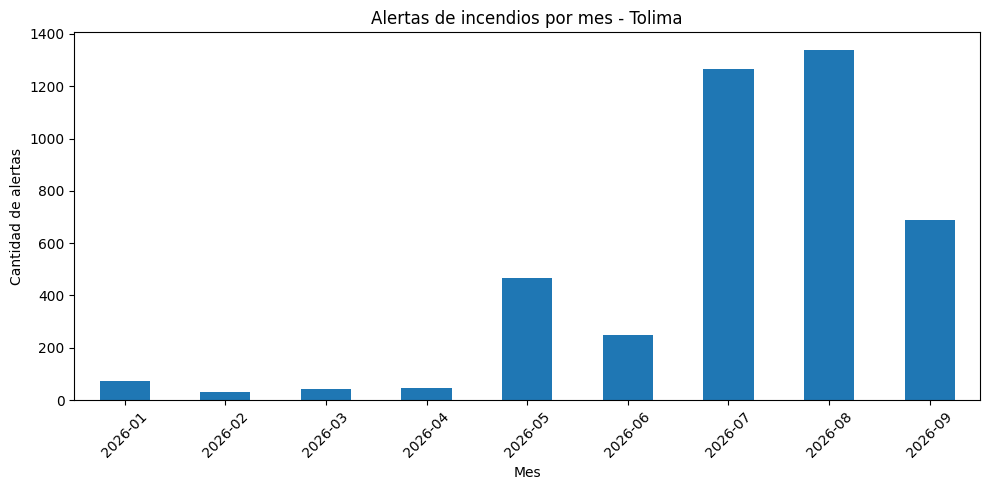

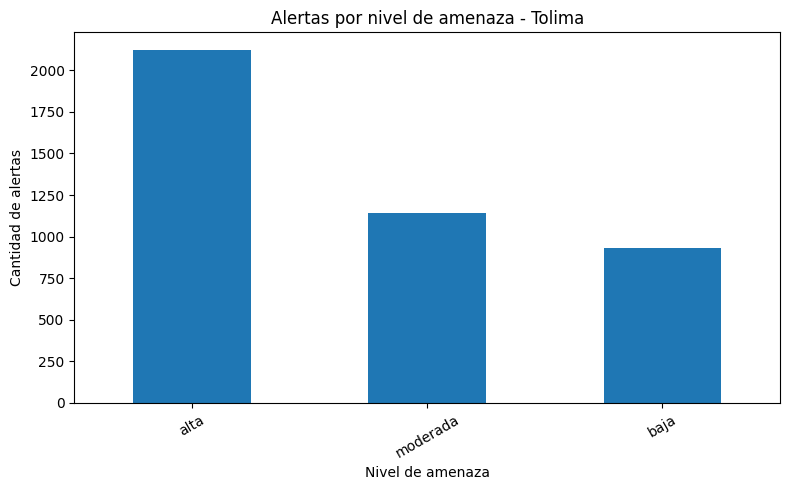

In [ ]:
#ANALISIS EXPLORATORIO INICIAL

import matplotlib.pyplot as plt

# Contar alertas por mes
alertas_por_mes = (
    df_integrado
    .dropna(subset=["FECHA_EJECUCION"])
    .assign(
        MES=lambda df: df["FECHA_EJECUCION"].dt.to_period("M")
    )
    .groupby("MES")
    .size()
)

# Grafico 1: cantidad de alertas por mes
alertas_por_mes.plot(kind="bar", figsize=(10, 5))

plt.title("Alertas de incendios por mes - Tolima")
plt.xlabel("Mes")
plt.ylabel("Cantidad de alertas")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Grafico 2: cantidad de alertas por nivel de amenaza
alertas_por_nivel = (
    df_integrado["TEXTO_AMENAZA"]
    .value_counts()
)

alertas_por_nivel.plot(kind="bar", figsize=(8, 5))

plt.title("Alertas por nivel de amenaza - Tolima")
plt.xlabel("Nivel de amenaza")
plt.ylabel("Cantidad de alertas")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [ ]:

# Revisar los departamentos que aparecen en las alertas
print("Departamentos en el CSV:")
print(df_incendios["DEPARTAMENTO"].value_counts().head(15))

# Revisar los departamentos del catálogo IDEAM
print("\nDepartamentos en el catálogo IDEAM:")
print(df_ideam["departamento"].value_counts().head(15))


Departamentos en el CSV:
DEPARTAMENTO
CUNDINAMARCA          6308
TOLIMA                4197
NARIÑO                3786
BOYACÁ                3523
ANTIOQUIA             2474
NORTE DE SANTANDER    2464
CAUCA                 2174
LA GUAJIRA            1867
HUILA                 1847
SANTANDER             1618
ATLÁNTICO             1578
MAGDALENA             1199
VALLE DEL CAUCA       1153
BOLÍVAR               1104
CESAR                  961
Name: count, dtype: int64

Departamentos en el catálogo IDEAM:
departamento
Antioquia             3070
Cundinamarca          2298
Valle Del Cauca       1674
Boyacá                1102
Santander             1082
Tolima                1042
Caldas                 890
Cauca                  782
Huila                  782
Bogotá                 742
Bolivar                636
Norte De Santander     594
Cesar                  554
La Guajira             518
Cordoba                464
Name: count, dtype: int64


In [ ]:

# Limpiar espacios y unificar mayúsculas en los nombres
municipios_alertas = set(
    df_incendios["MUNICIPIO"]
    .dropna()
    .astype(str)
    .str.strip()
    .str.upper()
)

municipios_ideam = set(
    df_ideam["municipio"]
    .dropna()
    .astype(str)
    .str.strip()
    .str.upper()
)

# Encontrar los municipios que aparecen en ambas fuentes
coincidencias = municipios_alertas.intersection(municipios_ideam)

print("Municipios coincidentes:", len(coincidencias))
print("Ejemplos de coincidencias:", sorted(coincidencias)[:20])


Municipios coincidentes: 833
Ejemplos de coincidencias: ['ABEJORRAL', 'ABRIAQUÍ', 'ACACÍAS', 'ACANDÍ', 'ACEVEDO', 'ACHÍ', 'AGRADO', 'AGUA DE DIOS', 'AGUACHICA', 'AGUADAS', 'AGUAZUL', 'AGUSTÍN CODAZZI', 'AIPE', 'ALBANIA', 'ALBÁN', 'ALCALÁ', 'ALDANA', 'ALEJANDRÍA', 'ALGARROBO', 'ALGECIRAS']


In [ ]:
#Prueba

In [ ]:
# ==========================================
# DIAGNÓSTICO DE LA FUENTE METEOROLÓGICA IDEAM
# ==========================================

import requests
import pandas as pd

# Dirección de la API de observaciones meteorológicas
url_meteorologia = "https://www.datos.gov.co/resource/57sv-p2fu.json"

# Filtro para consultar únicamente el departamento del Tolima
filtro_tolima = "upper(departamento) = 'TOLIMA'"

# ------------------------------------------
# 1. Consultar cantidad total y fechas disponibles
# ------------------------------------------

parametros_resumen = {
    "$select": (
        "count(*) as total, "
        "min(fechaobservacion) as fecha_minima, "
        "max(fechaobservacion) as fecha_maxima"
    ),
    "$where": filtro_tolima
}

respuesta_resumen = requests.get(
    url_meteorologia,
    params=parametros_resumen,
    timeout=60
)

respuesta_resumen.raise_for_status()

resumen_ideam = pd.DataFrame(respuesta_resumen.json())

print("RESUMEN DE DATOS METEOROLÓGICOS DE TOLIMA")
display(resumen_ideam)

# ------------------------------------------
# 2. Consultar las variables meteorológicas
# ------------------------------------------

parametros_sensores = {
    "$select": (
        "descripcionsensor, unidadmedida, count(*) as registros"
    ),
    "$where": filtro_tolima,
    "$group": "descripcionsensor, unidadmedida",
    "$order": "registros DESC",
    "$limit": 1000
}

respuesta_sensores = requests.get(
    url_meteorologia,
    params=parametros_sensores,
    timeout=60
)

respuesta_sensores.raise_for_status()

sensores_ideam = pd.DataFrame(respuesta_sensores.json())

print("\nVARIABLES METEOROLÓGICAS DISPONIBLES")
display(sensores_ideam)

# ------------------------------------------
# 3. Consultar registros del periodo de alertas
# ------------------------------------------

parametros_historicos = {
    "$select": "count(*) as total",
    "$where": (
        filtro_tolima
        + " AND fechaobservacion >= '2026-01-01T00:00:00'"
        + " AND fechaobservacion < '2026-09-20T00:00:00'"
    )
}

respuesta_historica = requests.get(
    url_meteorologia,
    params=parametros_historicos,
    timeout=60
)

respuesta_historica.raise_for_status()

historico_ideam = pd.DataFrame(respuesta_historica.json())

print("\nREGISTROS ENTRE ENERO Y SEPTIEMBRE DE 2026")
display(historico_ideam)

RESUMEN DE DATOS METEOROLÓGICOS DE TOLIMA


,total,fecha_minima,fecha_maxima
0,5874,2026-11-04T00:11:00.000,2026-11-04T11:40:00.000



VARIABLES METEOROLÓGICAS DISPONIBLES


,descripcionsensor,unidadmedida,registros
0,Precipitación acumulada 10 minutos,mm,2245
1,Velocidad del viento cada 10 minutos,m/s,1108
2,Dirección del viento cada 10 minutos,deg,1040
3,Humedad relativa del aire a 2 metros horaria,%,200
4,Temperatura del aire a 2 metros,°C,200
5,Temperatura mínima del Aire a 2 metros,°C,200
6,Temperatura máxima del Aire a 2 metros,°C,197
7,Presión atmosférica horaria,hPa,172
8,Nivel mínimo horario,cm,169
9,Nivel máximo horario,cm,167



REGISTROS ENTRE ENERO Y SEPTIEMBRE DE 2026


,total
0,0


In [ ]:
# Revisamos las fechas de las alertas de incendios

# Convertimos la columna a formato de fecha, si todavía no lo está
alertas_tolima["FECHA_EJECUCION"] = pd.to_datetime(
    alertas_tolima["FECHA_EJECUCION"],
    errors="coerce"
)

# Mostramos la fecha más antigua y la más reciente
print("Fecha inicial:", alertas_tolima["FECHA_EJECUCION"].min())
print("Fecha final:", alertas_tolima["FECHA_EJECUCION"].max())

# Contamos cuántas alertas hay por mes
print("\nAlertas por mes:")
print(alertas_tolima["FECHA_EJECUCION"].dt.to_period("M").value_counts().sort_index())

Fecha inicial: 2026-01-01 00:00:00
Fecha final: 2026-09-19 00:00:00

Alertas por mes:
FECHA_EJECUCION
2026-01      72
2026-02      29
2026-03      44
2026-04      45
2026-05     468
2026-06     249
2026-07    1264
2026-08    1339
2026-09     687
Freq: M, Name: count, dtype: int64
